# CSAD 模型（基于时序回归变形）

**用于构建羊群效应因子的行为金融模型**

* 每个月末，提取当前可交易股票过去 120 个交易日的涨跌幅数据，计算目标股票 $S_*$ 与其他股票（不活跃交易日不超过 20 天）之间的日涨跌幅相关系数；
  
* 选取与 $S_*$ 相关系数最大的 9 只股票，连同 $S_*$ 一起构成一个包含 10 只股票的"小型"板块：
  

$$
S_i, \quad i = 1, 2, \dots, 10
$$

* 以 $S_*$ 为中心股票，计算该板块过去 120 个交易日的横截面绝对偏差（CSAD）：

$$
\text{CSAD}_t = \frac{1}{10} \sum_{i=1}^{10} \left| r_{i,t} - r_{*,t} \right|
$$

其中，$r_{i,t}$ 为板块内第 $i$ 只股票在交易日 $t$ 的收益率，$r_{*,t}$ 为中心股票 $S_*$ 在交易日 $t$ 的收益率。

* 以 CSAD 波动率相对于个股波动率的比值变化作为羊群效应因子，分别计算短期比值和长期比值：

$$
\text{ratio}[t_1, t_2] = \frac{\sigma[t_1, t_2](\text{CSAD})}{\sigma[t_1, t_2](r_*)}
$$

其中，$\sigma[t_1, t_2](\text{CSAD})$ 为 CSAD 在时间段 $[t_1, t_2]$ 内的波动率（标准差），$\sigma[t_1, t_2](r_*)$ 为中心股票收益率在同一时间段内的波动率。

最终的羊群效应因子定义为近期比值与长期比值的比率：

$$
f_{jt} = \frac{\text{ratio}[t - 19, t]}{\text{ratio}[t - 119, t]}
$$

其中，分子 $\text{ratio}[t - 19, t]$ 为过去 20 个交易日的短期 CSAD 相对波动率比值，分母 $\text{ratio}[t - 119, t]$ 为过去 120 个交易日的长期 CSAD 相对波动率比值。

## 因子逻辑说明

标准的 CSAD 时序回归模型通过回归系数 $\beta_2$ 的显著性来检验羊群效应（$\beta_2$ 显著为负表明羊群效应存在），核心逻辑是：当羊群效应存在时，股票收益率的分散度（CSAD）随市场极端行情而减小的幅度，大于市场收益水平本身的变化幅度。

考虑到时序长度不足和滞后误差等因素的影响，本模型对标准时序回归方法进行了变形处理。通过比较 CSAD 波动率与中心股票波动率的比值在短期和长期的变化情况，避免了直接进行时序回归可能带来的估计偏差。当 $f_{jt} < 1$ 时，表明近期 CSAD 的相对波动率较长期水平有所下降，即板块内个股收益趋于一致，羊群效应增强，该板块受关注程度提升；反之，当 $f_{jt} > 1$ 时，表明羊群效应减弱。

In [1]:
import numpy as np
import pandas as pd

from rqdatac import (
    all_instruments,
    get_price,
    get_trading_dates,
)


def _csad_ratio_ids(stock_ids):
    if stock_ids is None:
        return (
            all_instruments("CS")["order_book_id"]
            .dropna()
            .drop_duplicates()
            .tolist()
        )

    if isinstance(stock_ids, str):
        return [stock_ids]

    return list(dict.fromkeys(stock_ids))


def _csad_ratio_get_returns_wide(
    order_book_ids,
    price_dates,
    batch_size=500,
):
    """下载复权收盘价并生成 日收益率宽表。"""
    parts = []

    for start in range(0, len(order_book_ids), batch_size):
        batch = order_book_ids[start:start + batch_size]

        raw = get_price(
            order_book_ids=batch,
            start_date=price_dates[0],
            end_date=price_dates[-1],
            frequency="1d",
            fields=["close", "volume"],
            adjust_type="pre",
            skip_suspended=False,
            expect_df=True,
        )

        if raw is None or raw.empty:
            continue

        if isinstance(raw.index, pd.MultiIndex):
            close = raw["close"].unstack("order_book_id")
            volume = raw["volume"].unstack("order_book_id")
        else:
            close = raw[["close"]].rename(columns={"close": batch[0]})
            volume = raw[["volume"]].rename(columns={"volume": batch[0]})

        close.index = pd.to_datetime(close.index)
        volume.index = pd.to_datetime(volume.index)

        close = close.reindex(index=price_dates, columns=batch)
        volume = volume.reindex(index=price_dates, columns=batch)

        stock_return = close.pct_change(fill_method=None).iloc[1:]

        # 停牌日不将“价格未变”当作真实零收益
        stock_return = stock_return.where(volume.iloc[1:].gt(0))
        parts.append(stock_return)

    if not parts:
        raise RuntimeError("未取得有效价格数据。")

    returns = pd.concat(parts, axis=1)
    returns = returns.loc[:, ~returns.columns.duplicated()]

    return returns.reindex(
        index=price_dates[1:],
        columns=order_book_ids,
    )


def _csad_ratio_month_end_dates(dates):
    """取每个月的最后一个交易日。"""
    month_index = pd.Index(dates.to_period("M"))

    return dates[
        ~month_index.duplicated(keep="last")
    ]


def _csad_ratio_select_boards(
    returns,
    rebalance_date,
    candidate_ids,
    corr_window=120,
    max_inactive_days=20,
    group_size=10,
):
    """
    在月末为每个中心股票选择 group_size - 1 个最高相关股票。
    """
    history = returns.loc[:rebalance_date].tail(corr_window)
    min_observations = corr_window - max_inactive_days

    # 同时要求：过去窗口足够活跃，且月末当日可交易
    eligible = (
        history.notna().sum(axis=0) >= min_observations
    )
    eligible = eligible & history.loc[rebalance_date].notna()

    eligible_ids = eligible[eligible].index.tolist()

    if len(eligible_ids) < group_size:
        return {}

    corr_matrix = history[eligible_ids].corr(
        min_periods=min_observations
    )

    boards = {}

    for stock in candidate_ids:
        if stock not in corr_matrix.columns:
            continue

        correlations = corr_matrix[stock].dropna()
        correlations = correlations[
            correlations.index != stock
        ]

        peers = correlations.nlargest(group_size - 1).index.tolist()

        if len(peers) == group_size - 1:
            boards[stock] = [stock] + peers

    return boards


def _csad_ratio_for_one_board(
    board_returns,
    center_stock,
    short_window=20,
    long_window=120,
    min_group_active=10,
):
    """
    计算固定小型板块的：
    ratio_short / ratio_long
    """
    center_return = board_returns[center_stock]

    active_count = board_returns.notna().sum(axis=1)

    csad = (
        board_returns.sub(center_return, axis=0)
        .abs()
        .mean(axis=1, skipna=True)
        .where(active_count >= min_group_active)
    )

    short_ratio = (
        csad.rolling(
            short_window,
            min_periods=short_window,
        ).std(ddof=1)
        / center_return.rolling(
            short_window,
            min_periods=short_window,
        ).std(ddof=1)
    )

    long_ratio = (
        csad.rolling(
            long_window,
            min_periods=long_window,
        ).std(ddof=1)
        / center_return.rolling(
            long_window,
            min_periods=long_window,
        ).std(ddof=1)
    )

    factor = short_ratio / long_ratio

    return factor.replace([np.inf, -np.inf], np.nan)


def calculate_center_board_csad_ratio_daily(
    start_date,
    end_date,
    candidate_ids=None,
    peer_universe_ids=None,
    corr_window=120,
    max_inactive_days=20,
    group_size=10,
    short_window=20,
    long_window=120,
    min_group_active=10,
    batch_size=500,
):
    """
    CSAD 模型（基于时序回归变形）

    每月末：
    1. 为每只中心股票选取 9 只最高相关股票；
    2. 形成中心股票 + 9 个同伴的小型板块；
    3. 计算 CSAD 相对中心股收益率的短期、长期波动率比值；
    4. 输出 short_ratio / long_ratio。

    输出：
        index  : [date, order_book_id]
        column : CSAD_TS_RATIO
    """
    if group_size < 2:
        raise ValueError("group_size 至少应为 2。")

    if min_group_active > group_size:
        raise ValueError(
            "min_group_active 不能大于 group_size。"
        )

    if short_window > long_window:
        raise ValueError(
            "short_window 不应大于 long_window。"
        )

    candidate_ids = _csad_ratio_ids(candidate_ids)
    peer_universe_ids = _csad_ratio_ids(peer_universe_ids)

    # 确保中心股票也在相关性候选池中
    all_ids = list(
        dict.fromkeys(candidate_ids + peer_universe_ids)
    )

    start_date = pd.Timestamp(start_date)
    end_date = pd.Timestamp(end_date)

    # 预留相关性窗口、长期波动率窗口及上一个月末的空间
    required_history = max(corr_window, long_window) + 25

    calendar = pd.DatetimeIndex(
        get_trading_dates(
            start_date=start_date - pd.Timedelta(
                days=max(required_history * 3, 365)
            ),
            end_date=end_date,
        )
    )

    target_dates = calendar[
        (calendar >= start_date) & (calendar <= end_date)
    ]

    if len(target_dates) == 0:
        raise ValueError("所选区间内没有交易日。")

    first_loc = calendar.get_loc(target_dates[0])
    last_loc = calendar.get_loc(target_dates[-1])

    if first_loc < required_history:
        raise ValueError("历史交易日不足，无法构建小型板块。")

    price_dates = calendar[
        first_loc - required_history:last_loc + 1
    ]

    returns = _csad_ratio_get_returns_wide(
        order_book_ids=all_ids,
        price_dates=price_dates,
        batch_size=batch_size,
    )

    # 找到开始日之前最近一个可用月末，
    # 使开始日可沿用该月末建立的小型板块。
    all_month_ends = _csad_ratio_month_end_dates(
        returns.index
    )

    valid_month_ends = []

    for date in all_month_ends:
        if returns.index.get_loc(date) >= corr_window - 1:
            valid_month_ends.append(date)

    valid_month_ends = pd.DatetimeIndex(valid_month_ends)
    valid_month_ends = valid_month_ends[
        valid_month_ends <= target_dates[-1]
    ]

    prior_rebalance_dates = valid_month_ends[
        valid_month_ends <= target_dates[0]
    ]

    if len(prior_rebalance_dates) == 0:
        raise ValueError(
            "开始日前缺少可用于建组的月末交易日。"
        )

    first_rebalance_date = prior_rebalance_dates[-1]
    rebalance_dates = valid_month_ends[
        valid_month_ends >= first_rebalance_date
    ]

    factor_wide = pd.DataFrame(
        index=target_dates,
        columns=candidate_ids,
        dtype=float,
    )

    # 每次月末建组，并将该组沿用至下一次月末建组前
    for pos, rebalance_date in enumerate(rebalance_dates):
        next_rebalance_date = (
            rebalance_dates[pos + 1]
            if pos + 1 < len(rebalance_dates)
            else None
        )

        if next_rebalance_date is None:
            segment_dates = target_dates[
                target_dates >= rebalance_date
            ]
        else:
            segment_dates = target_dates[
                (target_dates >= rebalance_date)
                & (target_dates < next_rebalance_date)
            ]

        if len(segment_dates) == 0:
            continue

        boards = _csad_ratio_select_boards(
            returns=returns,
            rebalance_date=rebalance_date,
            candidate_ids=candidate_ids,
            corr_window=corr_window,
            max_inactive_days=max_inactive_days,
            group_size=group_size,
        )

        # 需要取出本段之前的 long_window - 1 日，
        # 才能在本段首日计算长期波动率。
        segment_start_loc = returns.index.get_loc(
            segment_dates[0]
        )
        segment_end_loc = returns.index.get_loc(
            segment_dates[-1]
        )

        history_start_loc = max(
            0,
            segment_start_loc - long_window + 1,
        )

        calculation_dates = returns.index[
            history_start_loc:segment_end_loc + 1
        ]

        for stock, board in boards.items():
            board_returns = returns.loc[
                calculation_dates,
                board,
            ]

            factor = _csad_ratio_for_one_board(
                board_returns=board_returns,
                center_stock=stock,
                short_window=short_window,
                long_window=long_window,
                min_group_active=min_group_active,
            )

            factor_wide.loc[segment_dates, stock] = (
                factor.reindex(segment_dates)
            )

    result = (
        factor_wide
        .stack(dropna=True)
        .rename("CSAD_TS_RATIO")
        .to_frame()
    )
    result.index = result.index.set_names(
        ["date", "order_book_id"]
    )

    return result

In [ ]:
from rqdatac import index_components

# 沪深300
hs300_ids = index_components(
    "000300.XSHG",
    date="2025-12-31",
)

csad_ts_ratio = calculate_center_board_csad_ratio_daily(
    start_date="2020-01-01",
    end_date="2025-12-31",
    candidate_ids=hs300_ids,
    peer_universe_ids=hs300_ids,
    corr_window=120,
    max_inactive_days=20,
    group_size=10,
    short_window=20,
    long_window=120,
    min_group_active=10,
    batch_size=500,
)

csad_ts_ratio.head()

In [3]:
# 计算量非常大

all_a_parts = []

for year in [2020, 2021, 2022, 2023, 2024, 2025]:
    factor_part = calculate_center_board_csad_ratio_daily(
        start_date="{}-01-01".format(year),
        end_date="{}-12-31".format(year),
        candidate_ids=None,
        peer_universe_ids=None,
        corr_window=120,
        max_inactive_days=20,
        group_size=10,
        short_window=20,
        long_window=120,
        min_group_active=10,
    )

    all_a_parts.append(factor_part)
    print(1)

csad_ts_ratio = pd.concat(all_a_parts).sort_index()

1
1
1
1
1
1


In [5]:
csad_ts_ratio_df = csad_ts_ratio.unstack(level="order_book_id")

In [5]:
import pandas as pd
from rqfactor.notebook import factor_analysis

# 原 CSV：索引是 date、order_book_id 两层
csad_ts_ratio_panel = pd.read_csv(
    "csad_ts_ratio.csv",
    index_col=[0, 1],
    parse_dates=[0],
)

csad_ts_ratio_panel.index = csad_ts_ratio_panel.index.set_names(
    ["date", "order_book_id"]
)

# 转为米筐因子测试要求的宽表
csad_ts_ratio_factor_data = (
    csad_ts_ratio_panel["CSAD_TS_RATIO"]
    .unstack("order_book_id")
    .sort_index()
)

csad_ts_ratio_factor_data.columns = (
    csad_ts_ratio_factor_data.columns.astype(str)
)
csad_ts_ratio_factor_data.columns.name = "order_book_id"

csad_ts_ratio_factor_data

order_book_id,000001.XSHE,000002.XSHE,000004.XSHE,000005.XSHE,000006.XSHE,000007.XSHE,000008.XSHE,000009.XSHE,000010.XSHE,000011.XSHE,...,688787.XSHG,688788.XSHG,688789.XSHG,688793.XSHG,688798.XSHG,688799.XSHG,688800.XSHG,688819.XSHG,688981.XSHG,689009.XSHG
date,,,,,,,,,,,,,,,,,,,,,
2020-01-02,0.608953,1.304266,NaN,0.856990,0.386461,1.272581,1.384343,0.988399,0.749791,0.519716,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2020-01-03,0.673737,1.232464,NaN,0.828557,0.490103,1.279589,1.478637,0.960709,0.734992,0.545225,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2020-01-06,0.685957,1.171649,NaN,0.829950,0.490668,1.280240,1.549696,0.980573,0.692061,0.550962,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2020-01-07,0.730222,1.168916,NaN,0.853546,0.572504,1.351043,1.279862,0.994256,0.723696,0.627541,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2020-01-08,0.656295,1.192882,NaN,0.813698,0.533497,1.347895,1.172168,0.989224,0.699412,0.571511,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2025-12-25,1.458193,0.968635,0.956101,NaN,0.993846,1.122233,0.872553,0.839687,0.840361,0.662875,...,0.614335,NaN,0.919356,0.731149,0.997837,0.954578,1.201416,NaN,NaN,1.204479
2025-12-26,1.478155,0.987179,1.008717,NaN,1.034698,1.099131,0.968768,0.846693,0.837580,0.660273,...,0.812835,NaN,0.934223,1.273525,1.015800,0.880392,1.185195,NaN,NaN,1.026038
2025-12-29,1.419710,0.987987,1.034524,NaN,0.723126,1.073695,0.983963,0.676319,0.837493,0.392222,...,0.833639,NaN,0.972063,1.273256,0.736216,0.889170,1.186112,NaN,NaN,1.431214


In [6]:
result_csad_ts_ratio = factor_analysis(
    f=csad_ts_ratio_factor_data,
    period=1,
    shift=1,
    rank_ic=True,
    quantile=5,
    ascending=True,
    winzorization="mad",
    normalization=False,
    neutralization="none",
    include_st=False,
    include_new=False,
    benchmark="000985.XSHG",
)

result_csad_ts_ratio.show()

Loading BokehJS ...

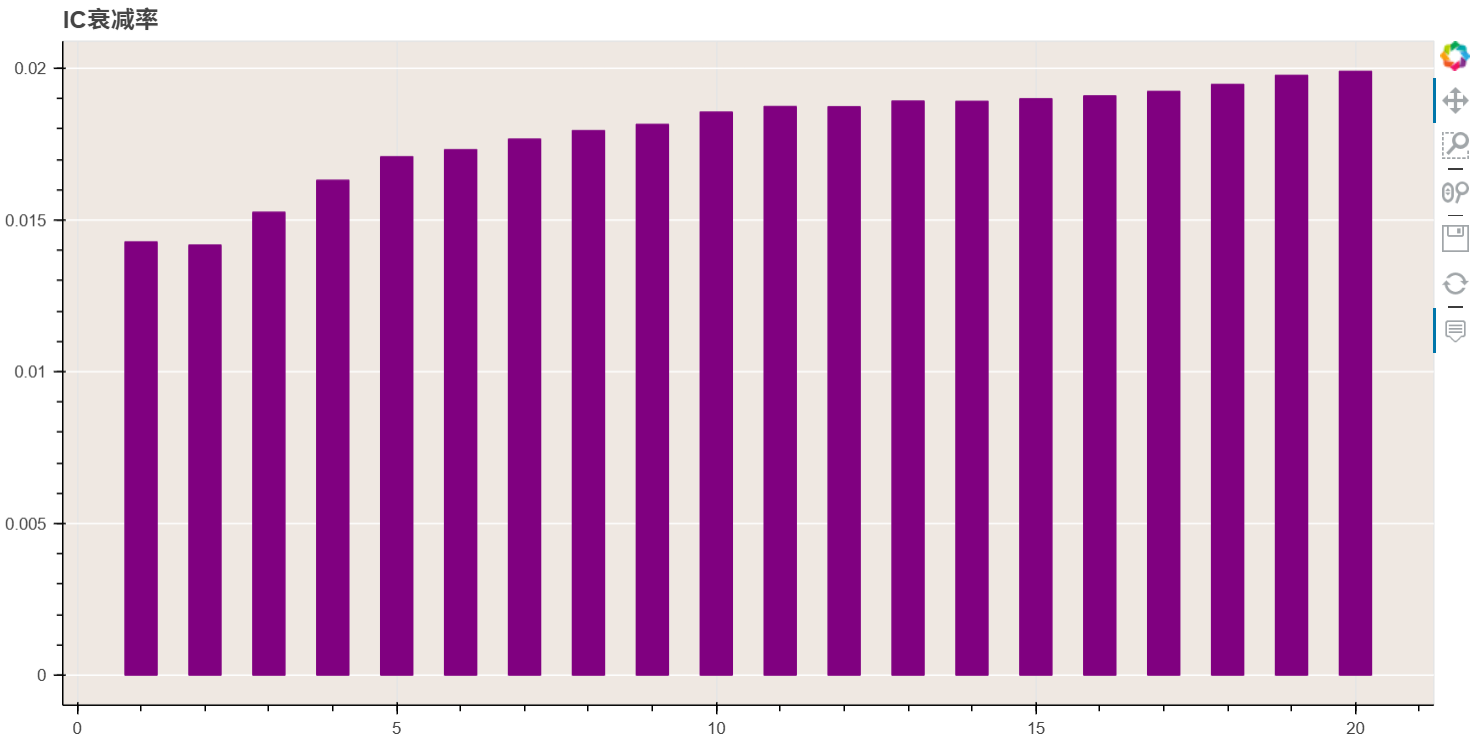

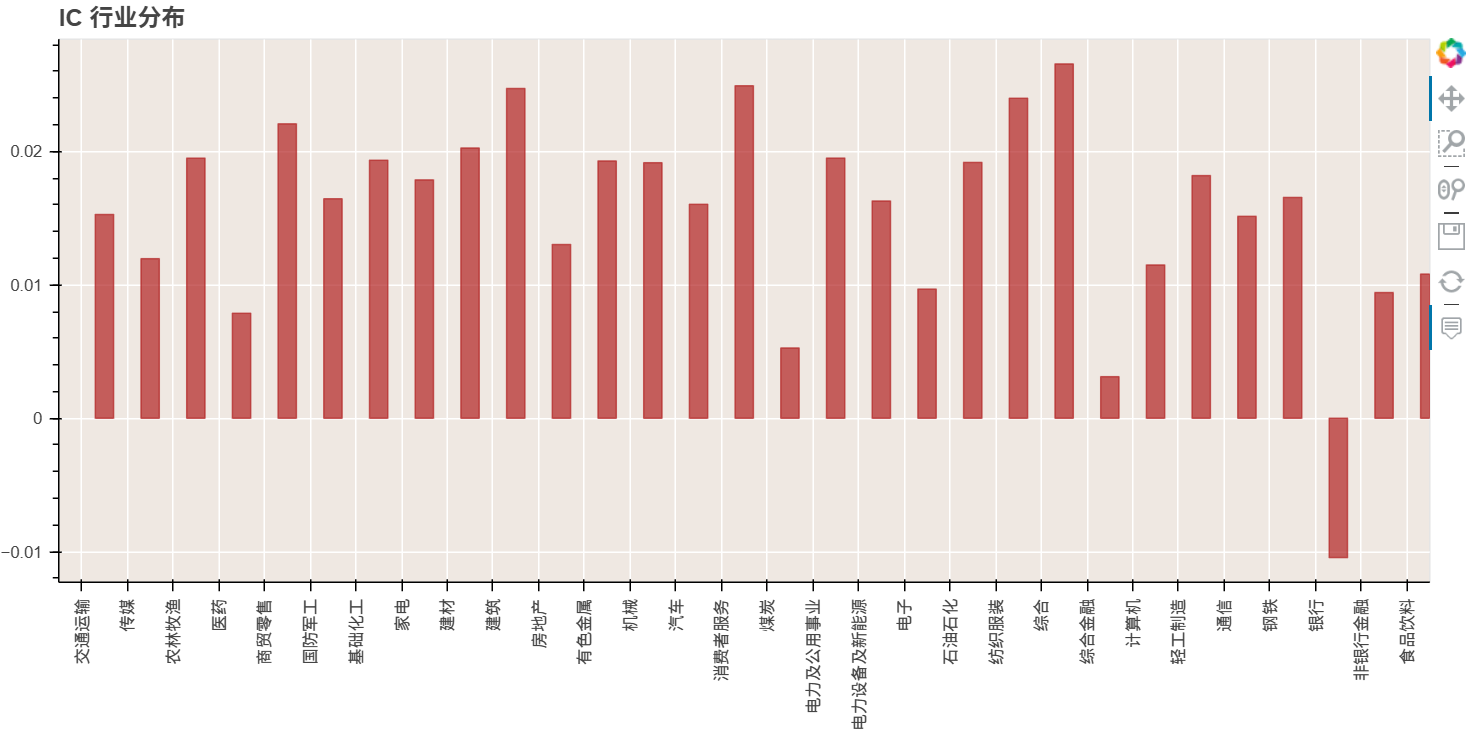

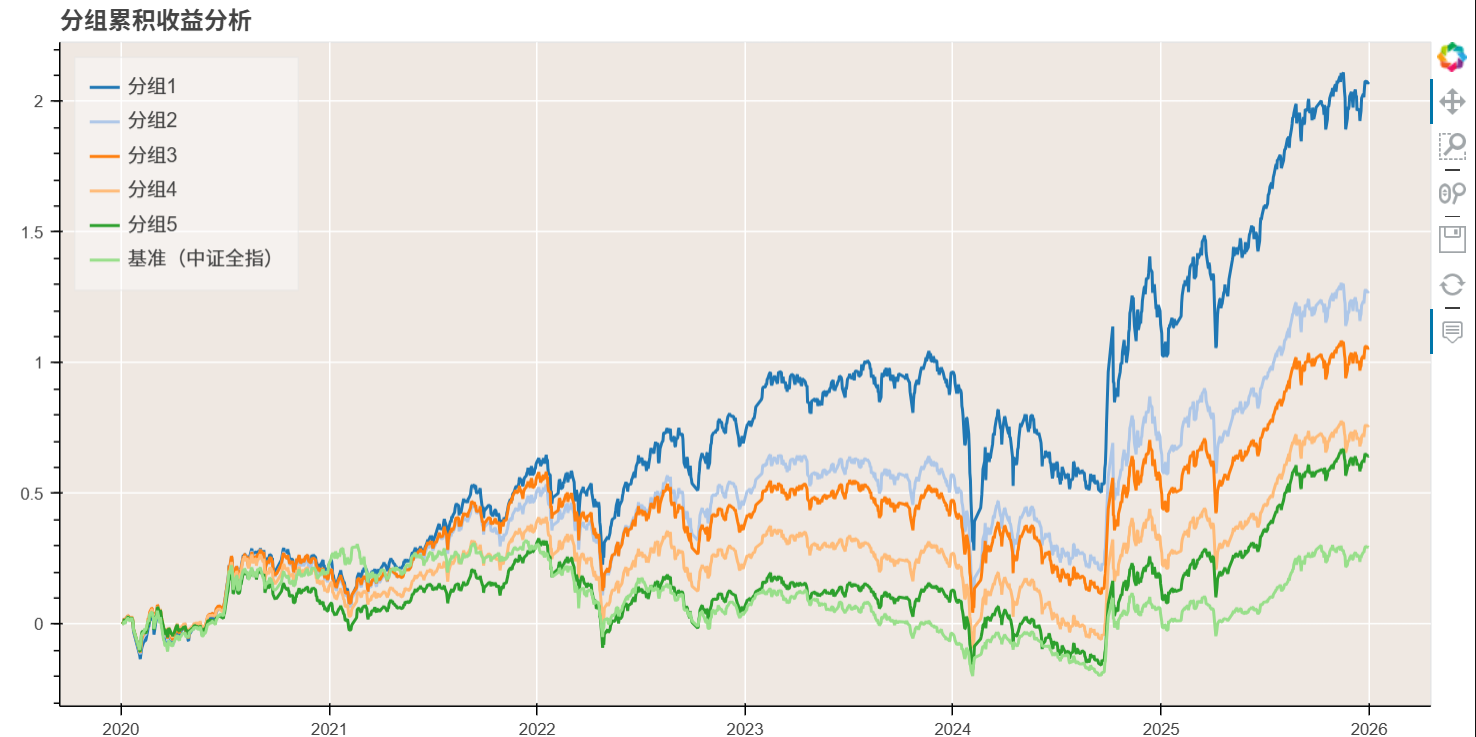

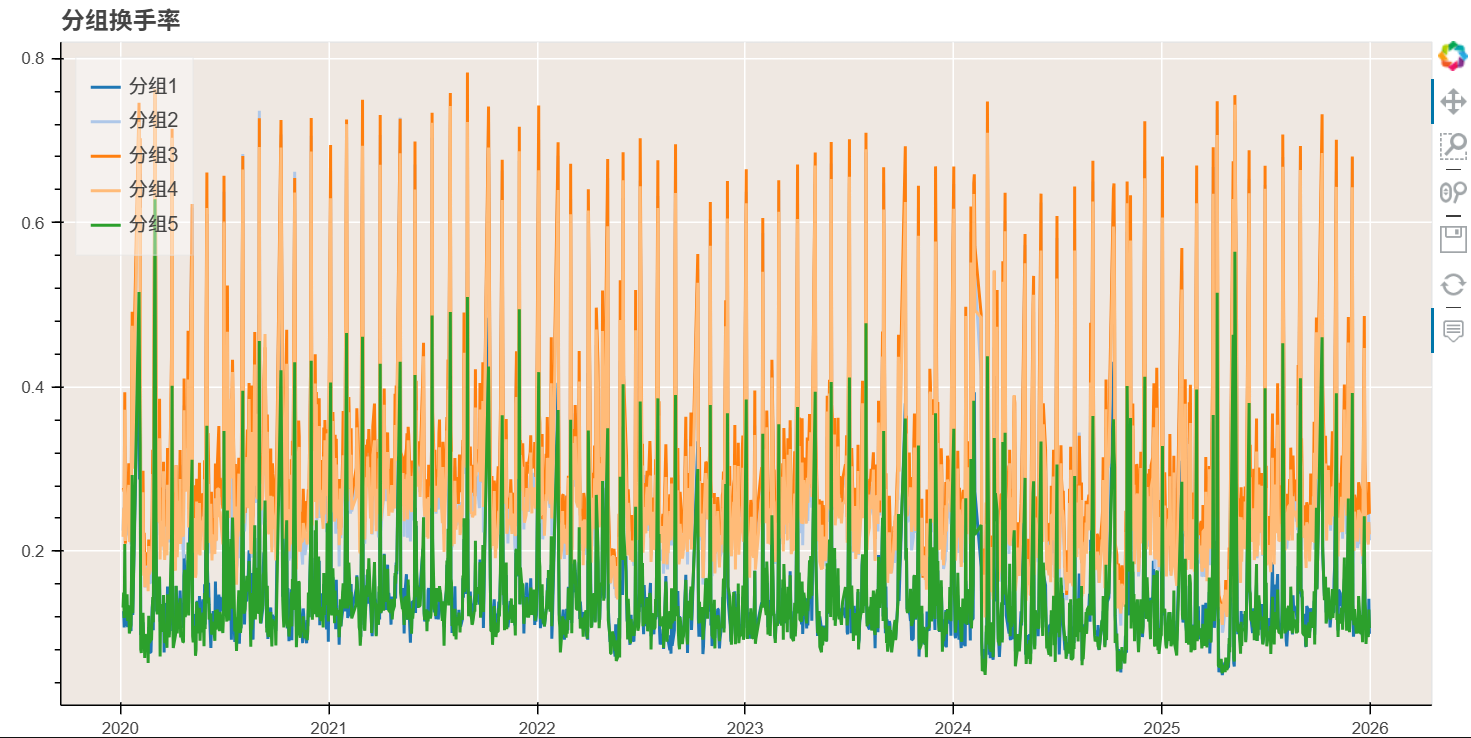

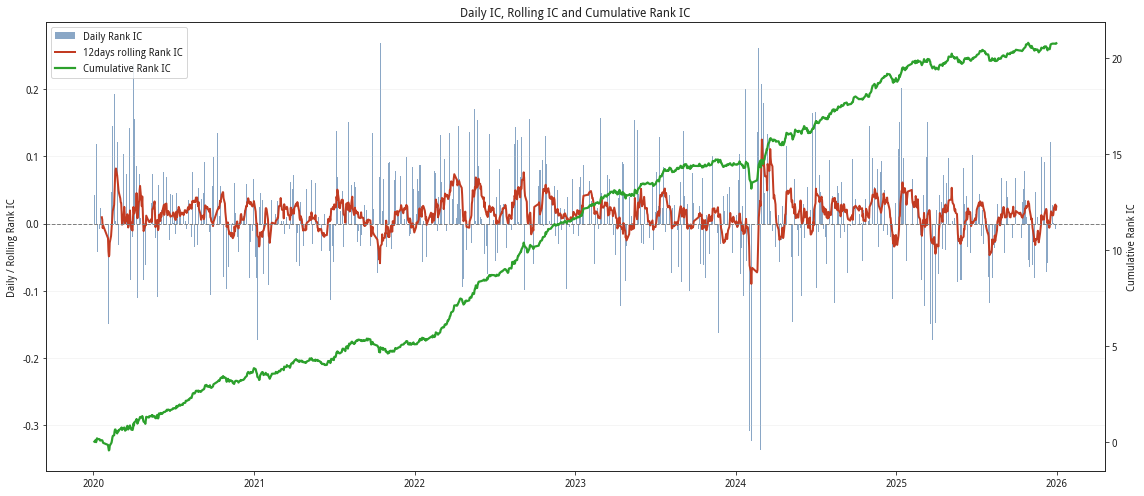

In [7]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

# 替换为你的五年因子测试结果变量
ic = result_csad_ts_ratio.ic.dropna()

rolling_window = 12  # 可改为 12，与米筐默认图保持一致
rolling_ic = ic.rolling(rolling_window).mean()
cum_ic = ic.cumsum()

plt.rcParams.update({
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "savefig.facecolor": "white",
    "axes.edgecolor": "#222222",
    "axes.labelcolor": "#222222",
    "xtick.color": "#222222",
    "ytick.color": "#222222",
    "text.color": "#222222",
    "grid.color": "#D0D0D0",
})

fig, ax1 = plt.subplots(figsize=(16, 7))

# 左轴：每日 IC 柱状图 + 滚动 IC
bars = ax1.bar(
    ic.index,
    ic,
    width=0.8,
    color="#4C78A8",
    alpha=0.65,
    label="Daily Rank IC",
)

line_roll, = ax1.plot(
    rolling_ic.index,
    rolling_ic,
    color="#C23B22",
    linewidth=2,
    label=f"{rolling_window}days rolling Rank IC",
)

ax1.axhline(0, color="gray", linewidth=1, linestyle="--")
ax1.set_ylabel("Daily / Rolling Rank IC")
ax1.set_title("Daily IC, Rolling IC and Cumulative Rank IC")

# 右轴：累计 IC
ax2 = ax1.twinx()

line_cum, = ax2.plot(
    cum_ic.index,
    cum_ic,
    color="#2CA02C",
    linewidth=2.2,
    label="Cumulative Rank IC",
)

ax2.set_ylabel("Cumulative Rank IC")

# 横轴日期格式
ax1.xaxis.set_major_locator(mdates.YearLocator())
ax1.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
ax1.grid(axis="y", alpha=0.25)

# 合并双轴图例
ax1.legend(
    [bars, line_roll, line_cum],
    ["Daily Rank IC", f"{rolling_window}days rolling Rank IC", "Cumulative Rank IC"],
    loc="upper left",
)

fig.tight_layout()
plt.show()